In [ ]:
# --- project bootstrap: run from anywhere, keeps data/ and figures/ paths working ---
import os, sys
from pathlib import Path
_here = Path.cwd()
if _here.name == "notebooks":          # notebook lives in notebooks/, project root is one level up
    os.chdir(_here.parent)
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))  # makes `from coherence import ...` available
os.makedirs("data", exist_ok=True); os.makedirs("figures", exist_ok=True)
print("project root:", ROOT)


In [1]:
# Cell 1 — imports + folders
import scqubits as scq, numpy as np, pandas as pd
import matplotlib.pyplot as plt, os
os.makedirs('data', exist_ok=True)
os.makedirs('figures', exist_ok=True)
scq.settings.T1_DEFAULT_WARNING = False   # silence the harmless t1 warning

In [2]:
# Cell 2 — coherence for one transmon (all times returned in microseconds)
def transmon_coherence(EJ, EC, ng=0.0, ncut=30,
                       Q_cap=1e6, A_ng=1e-4, A_cc=1e-7):
    tm = scq.Transmon(EJ=EJ, EC=EC, ng=ng, ncut=ncut)
    T1      = tm.t1_capacitive(i=1, j=0, Q_cap=Q_cap)        # dielectric relaxation
    Tphi_ng = tm.tphi_1_over_f_ng(A_noise=A_ng, i=0, j=1)    # charge dephasing
    Tphi_cc = tm.tphi_1_over_f_cc(A_noise=A_cc, i=0, j=1)    # critical-current dephasing
    T2 = 1.0 / (1.0/(2*T1) + 1.0/Tphi_ng + 1.0/Tphi_cc)      # add RATES
    ev = tm.eigenvals(evals_count=2)
    return {'EJ': EJ, 'EC': EC, 'EJ_EC': EJ/EC, 'freq_GHz': ev[1]-ev[0],
            'T1_us': T1*1e-3, 'Tphi_ng_us': Tphi_ng*1e-3,
            'Tphi_cc_us': Tphi_cc*1e-3, 'T2_us': T2*1e-3}

# sanity check on the Week-1 point
print(transmon_coherence(15.0, 0.3))

{'EJ': 15.0, 'EC': 0.3, 'EJ_EC': 50.0, 'freq_GHz': np.float64(5.682575677294973), 'T1_us': np.float64(28.020774270685706), 'Tphi_ng_us': np.float64(595764782448169.4), 'Tphi_cc_us': np.float64(1802.9226903331476), 'T2_us': np.float64(54.35208346332045)}


In [3]:
# Cell 3 — the sweep (40 EJ x 20 EC = 800 points, ~2 min)
EJ_grid = np.linspace(1, 80, 40)
EC_grid = np.linspace(0.1, 2.0, 20)

rows = []
for EJ in EJ_grid:
    for EC in EC_grid:
        try:
            rows.append(transmon_coherence(EJ, EC))
        except Exception:
            rows.append({'EJ': EJ, 'EC': EC, 'EJ_EC': EJ/EC, 'freq_GHz': np.nan,
                         'T1_us': np.nan, 'Tphi_ng_us': np.nan,
                         'Tphi_cc_us': np.nan, 'T2_us': np.nan})

df = pd.DataFrame(rows)
df.to_csv('data/transmon_full_sweep.csv', index=False)   # SAVE before plotting
print(len(df), "points saved to data/transmon_full_sweep.csv")

800 points saved to data/transmon_full_sweep.csv


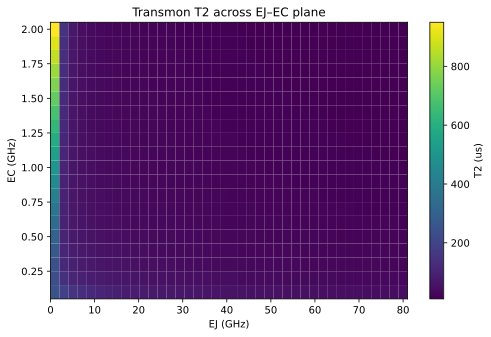

Best T2: 949.8 us at EJ= 1.0 EC= 2.0 (EJ/EC= 0.5 )
Best T2 in TRANSMON regime (EJ/EC>=20): 187.0 us at EJ= 3.0 EC= 0.1 (EJ/EC= 30.3 )


In [4]:
# Cell 4 — T2 heatmap over the EJ-EC plane (Q1)
pivot = df.pivot(index='EC', columns='EJ', values='T2_us')
plt.figure(figsize=(8, 5))
plt.pcolormesh(pivot.columns, pivot.index, pivot.values, shading='auto')
plt.colorbar(label='T2 (us)')
plt.xlabel('EJ (GHz)'); plt.ylabel('EC (GHz)')
plt.title('Transmon T2 across EJ–EC plane')
plt.savefig('figures/transmon_T2_map.png', dpi=150, bbox_inches='tight')
plt.show()

best = df.loc[df['T2_us'].idxmax()]
print("Best T2:", round(best.T2_us,1), "us at EJ=", round(best.EJ,1),
      "EC=", round(best.EC,2), "(EJ/EC=", round(best.EJ_EC,1), ")")
real = df[df.EJ_EC >= 20]
best_r = real.loc[real['T2_us'].idxmax()]
print("Best T2 in TRANSMON regime (EJ/EC>=20):", round(best_r.T2_us,1),
      "us at EJ=", round(best_r.EJ,1), "EC=", round(best_r.EC,2),
      "(EJ/EC=", round(best_r.EJ_EC,1), ")")

In [5]:
# Cell 5 — which channel dominates where (Q2)
def dominant(r):
    rates = {'relaxation(T1)': 1/(2*r.T1_us),
             'charge':         1/r.Tphi_ng_us,
             'crit-current':   1/r.Tphi_cc_us}
    return max(rates, key=rates.get)

df['dominant'] = df.apply(dominant, axis=1)
print(df['dominant'].value_counts())
print("\nCharge-dominated points cluster at LOW EJ/EC:")
print(df[df.dominant=='charge']['EJ_EC'].describe()[['min','max']])

dominant
relaxation(T1)    800
Name: count, dtype: int64

Charge-dominated points cluster at LOW EJ/EC:
min   NaN
max   NaN
Name: EJ_EC, dtype: float64


In [6]:
# Cell 6 — same sweep OFF the charge sweet spot (ng=0.25) to reveal the crossover
rows2 = []
for EJ in EJ_grid:
    for EC in EC_grid:
        try:
            rows2.append(transmon_coherence(EJ, EC, ng=0.25))
        except Exception:
            rows2.append({'EJ':EJ,'EC':EC,'EJ_EC':EJ/EC,'freq_GHz':np.nan,
                          'T1_us':np.nan,'Tphi_ng_us':np.nan,'Tphi_cc_us':np.nan,'T2_us':np.nan})
df2 = pd.DataFrame(rows2)
df2.to_csv('data/transmon_sweep_ng025.csv', index=False)
df2['dominant'] = df2.apply(dominant, axis=1)
print(df2['dominant'].value_counts())
print("\nCharge-dominated EJ/EC range:")
print(df2[df2.dominant=='charge']['EJ_EC'].describe()[['min','max','count']])

dominant
relaxation(T1)    535
charge            265
Name: count, dtype: int64

Charge-dominated EJ/EC range:
min        0.50000
max       25.31339
count    265.00000
Name: EJ_EC, dtype: float64


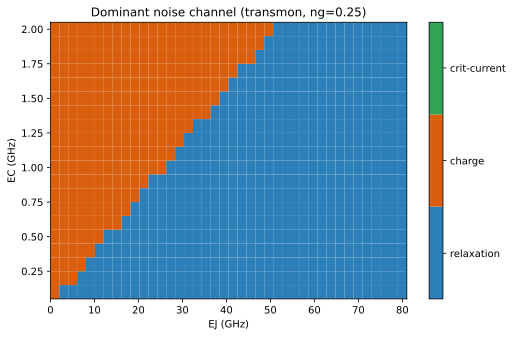

In [7]:
# Cell 7 — dominant-channel map (ng=0.25) — the Q2 figure
from matplotlib.colors import ListedColormap
cats = {'relaxation(T1)': 0, 'charge': 1, 'crit-current': 2}
df2['dom_code'] = df2['dominant'].map(cats)
grid = df2.pivot(index='EC', columns='EJ', values='dom_code')

cmap = ListedColormap(['#2c7fb8', '#d95f0e', '#31a354'])
plt.figure(figsize=(8, 5))
plt.pcolormesh(grid.columns, grid.index, grid.values,
               cmap=cmap, vmin=0, vmax=2, shading='auto')
cbar = plt.colorbar(ticks=[0.33, 1.0, 1.67])
cbar.ax.set_yticklabels(['relaxation', 'charge', 'crit-current'])
plt.xlabel('EJ (GHz)'); plt.ylabel('EC (GHz)')
plt.title('Dominant noise channel (transmon, ng=0.25)')
plt.savefig('figures/transmon_dominant_map.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
# Cell 8 — save run metadata next to the data
import json, datetime
meta = {
    'date': str(datetime.date.today()),
    'qubit': 'Transmon',
    'sweep': 'EJ [1,80]x40  x  EC [0.1,2.0]x20  = 800 points',
    'fixed_params': {'ncut': 30, 'Q_cap': 1e6, 'A_ng': 1e-4, 'A_cc': 1e-7},
    'ng_runs': {'sweet_spot': 0.0, 'off_sweet_spot': 0.25},
    'noise_channels': ['t1_capacitive', 'tphi_1_over_f_ng', 'tphi_1_over_f_cc'],
    'units': 'coherence times in microseconds (scqubits returns ns; multiply by 1e-3)',
    'files': ['data/transmon_full_sweep.csv', 'data/transmon_sweep_ng025.csv'],
}
with open('data/transmon_sweep_metadata.json', 'w') as f:
    json.dump(meta, f, indent=2)
print('metadata saved:\n', json.dumps(meta, indent=2))

metadata saved:
 {
  "date": "2026-08-04",
  "qubit": "Transmon",
  "sweep": "EJ [1,80]x40  x  EC [0.1,2.0]x20  = 800 points",
  "fixed_params": {
    "ncut": 30,
    "Q_cap": 1000000.0,
    "A_ng": 0.0001,
    "A_cc": 1e-07
  },
  "ng_runs": {
    "sweet_spot": 0.0,
    "off_sweet_spot": 0.25
  },
  "noise_channels": [
    "t1_capacitive",
    "tphi_1_over_f_ng",
    "tphi_1_over_f_cc"
  ],
  "units": "coherence times in microseconds (scqubits returns ns; multiply by 1e-3)",
  "files": [
    "data/transmon_full_sweep.csv",
    "data/transmon_sweep_ng025.csv"
  ]
}
